---
title: "Лабораторна робота 5. Ідентифікація та калібрування математичної моделі за даними"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

У попередніх лабораторних роботах ми послідовно будували модель і досліджували її поведінку:

$$
\text{Model Specification v0.1}
\rightarrow
\text{Dynamic Model Specification v0.2}
\rightarrow
\text{Network Model Specification v0.3}
\rightarrow
\text{Network Dynamics Specification v0.4}.
$$

Тепер змінюємо напрям задачі.

Раніше:

$$
\text{parameters}
\rightarrow
\text{model}
\rightarrow
\text{output}.
$$

У ЛР5:

$$
\text{observations}
+
\text{model structure}
\rightarrow
\text{parameter estimates}.
$$

Тобто переходимо від *прямої задачі (direct problem)* до *оберненої задачі (inverse problem)* [@gubarev2019; @bruntonKutz2022].
:::

# Мета роботи

Набути практичної здатності формулювати задачу ідентифікації та калібрування параметрів математичної моделі за даними, задавати observation model і loss function, оцінювати параметри чисельною оптимізацією, досліджувати practical identifiability та критично інтерпретувати результат калібрування.

# Завдання роботи

1. Відокремити model structure, parameters, states та observations.
2. Побудувати synthetic calibration dataset із контрольованим ground truth.
3. Сформулювати direct та inverse problem.
4. Визначити observation model.
5. Задати loss function.
6. Провести one-parameter calibration.
7. Дослідити loss profile.
8. Провести two-parameter calibration.
9. Побудувати loss surface.
10. Перевірити залежність optimizer від initial guess.
11. Проаналізувати residuals.
12. Продемонструвати practical non-identifiability за недостатніх даних.
13. Розрізнити calibration fit та validation.
14. Перенести процедуру на власний дисертаційний об'єкт.
15. Сформувати *Calibration Specification v0.5*.

# Теоретичний мінімум

Нехай математична модель має вигляд

$$
\dot{x}
=
f(x,u,\theta),
$$

де:

- $x(t)$ -- state;
- $u(t)$ -- input;
- $\theta$ -- vector of unknown parameters.

Модель породжує prediction

$$
\hat{y}_i(\theta)
=
h(x(t_i;\theta)).
$$

Спостереження:

$$
y_i
=
\hat{y}_i(\theta)
+
\varepsilon_i.
$$

Калібрування формулюємо як optimization problem:

$$
\hat{\theta}
=
\arg\min_{\theta\in\Theta}
J(\theta),
$$

де, наприклад,

$$
J(\theta)
=
\sum_{i=1}^{n}
\left[
y_i-\hat{y}_i(\theta)
\right]^2.
$$

Але мінімум $J$ ще не гарантує, що параметри однозначно визначаються даними [@gubarev2019].

## Логіка лабораторної роботи

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Model<br/>structure") --> B("Unknown<br/>parameters")
 B --> C("Observation<br/>model")
 C --> D("Loss<br/>function")
 D --> E("Optimization")
 E --> F("Parameter<br/>estimate")
 F --> G("Identifiability<br/>audit")
 G --> H("Calibration<br/>Specification v0.5")
```

# Частина I. Навчальний кейс

Використаємо логістичну модель зростання:

$$
\frac{dx}{dt}
=
r x
\left(
1-\frac{x}{K}
\right),
$$

де:

- $r>0$ -- intrinsic growth rate;
- $K>0$ -- carrying capacity.

Ця модель достатньо проста для прозорого аналізу, але вже має два параметри, між якими за обмежених observations може виникати practical identifiability problem.

Research Question:

> *Наскільки точно параметри $r$ і $K$ можуть бути відновлені з noisy observations trajectory та як інформаційність даних впливає на результат калібрування?*

# 1. Імпорт бібліотек і відтворюваність

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.optimize import minimize_scalar

BASE_SEED = 42
rng = np.random.default_rng(BASE_SEED)

# 2. Model structure

Запишемо праву частину ODE та solver.

Важливо відокремити:

$$
\text{model structure}
\neq
\text{parameter values}.
$$

У цьому кейсі structure фіксована, а

$$
\theta=(r,K)
$$

потрібно оцінити.

In [20]:
def logistic_rhs(t, x, r, K):
    return r * x * (1 - x / K)

def simulate_logistic(
    t_obs,
    r,
    K,
    x0
):
    solution = solve_ivp(
        fun=lambda t, x:
            logistic_rhs(t, x, r, K),
        t_span=(t_obs[0], t_obs[-1]),
        y0=[x0],
        t_eval=t_obs,
        rtol=1e-9,
        atol=1e-11
    )

    if not solution.success:
        raise RuntimeError(
            "Чисельне інтегрування неуспішне"
        )

    return solution.y[0]

# 3. Synthetic ground truth

Для навчального experiment ми знаємо true parameters:

$$
r^*=0.8,
\qquad
K^*=100.
$$

Початковий стан:

$$
x(0)=5.
$$

У реальному дослідженні ground truth параметрів зазвичай невідомий. Тут він потрібен для перевірки того, чи calibration procedure здатна відновити відомі значення.

In [21]:
R_TRUE = 0.8
K_TRUE = 100.0
X0 = 5.0

t_obs = np.linspace(
    0.0,
    10.0,
    21
)

x_true = simulate_logistic(
    t_obs,
    r=R_TRUE,
    K=K_TRUE,
    x0=X0
)

# 4. Observation model

Нехай вимірювання містять additive Gaussian noise:

$$
y_i
=
x(t_i;\theta^*)
+
\varepsilon_i,
$$

$$
\varepsilon_i
\sim
\mathcal{N}(0,\sigma^2).
$$

Візьмемо

$$
\sigma=2.
$$

Це *assumption of the observation model*, а не властивість самої logistic dynamics.

In [22]:
SIGMA = 2.0

y_obs = (
    x_true
    + rng.normal(
        loc=0.0,
        scale=SIGMA,
        size=len(t_obs)
    )
)

data = pd.DataFrame({
    "t": t_obs,
    "y_obs": y_obs,
    "x_true": x_true
})

data.head()

,t,y_obs,x_true
0,0.0,5.609434,5.000000
1,0.5,5.200129,7.280097
2,1.0,11.986105,10.485202
3,1.5,16.756127,14.874998
4,2.0,16.776031,20.678102


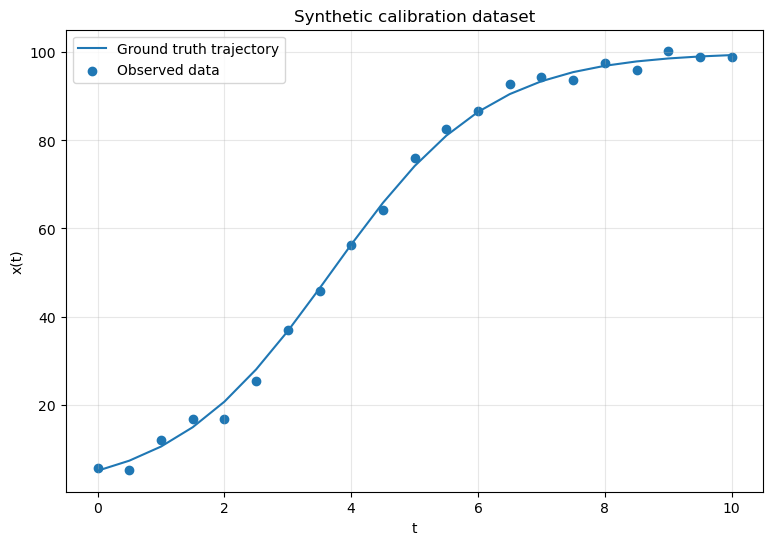

In [23]:
plt.figure(figsize=(9, 6))
plt.plot(
    t_obs,
    x_true,
    label="Ground truth trajectory"
)
plt.scatter(
    t_obs,
    y_obs,
    label="Observed data"
)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Synthetic calibration dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 4.1

Поясніть різницю між:

- process model;
- observation model;
- process uncertainty;
- measurement noise.

Чому додавання noise до synthetic data не означає, що сама logistic model стала stochastic?

# 5. Direct problem

За відомих

$$
r,
\quad
K,
\quad
x_0
$$

обчислюємо

$$
x(t;r,K).
$$

Це direct problem:

$$
(r,K)
\rightarrow
x(t).
$$

# 6. Inverse problem

Тепер маємо observations

$$
\{(t_i,y_i)\}_{i=1}^{n}
$$

і шукаємо

$$
(r,K).
$$

Тобто:

$$
\{y_i\}
+
\text{model}
\rightarrow
(\hat r,\hat K).
$$

Саме це є parameter identification / calibration problem [@gubarev2019].

# 7. Loss function

Використаємо sum of squared errors:

$$
J(r,K)
=
\sum_{i=1}^{n}
\left[
y_i-x(t_i;r,K)
\right]^2.
$$

Для порівняння моделей з однаковою кількістю observations також зручно використовувати

$$
RMSE
=
\sqrt{
\frac{1}{n}
\sum_i
(y_i-\hat y_i)^2
}.
$$

In [24]:
def sse_loss(
    params,
    t,
    y,
    x0
):
    r, K = params

    if r <= 0 or K <= 0:
        return np.inf

    y_hat = simulate_logistic(
        t,
        r=r,
        K=K,
        x0=x0
    )

    residuals = y - y_hat

    return np.sum(
        residuals ** 2
    )

def rmse(y, y_hat):
    return np.sqrt(
        np.mean(
            (y - y_hat) ** 2
        )
    )

# 8. Спочатку -- one-parameter calibration

Щоб побачити механіку calibration максимально прозоро, спочатку вважатимемо $K$ відомим:

$$
K=100.
$$

Шукаємо лише

$$
\hat r
=
\arg\min_r J(r,K^*).
$$

In [25]:
def loss_r_only(r):
    return sse_loss(
        params=(r, K_TRUE),
        t=t_obs,
        y=y_obs,
        x0=X0
    )

result_r = minimize_scalar(
    loss_r_only,
    bounds=(0.1, 1.5),
    method="bounded"
)

r_hat_1d = result_r.x

print(
    "True r:",
    R_TRUE
)

print(
    "Estimated r:",
    round(r_hat_1d, 4)
)

print(
    "SSE:",
    round(result_r.fun, 4)
)

True r: 0.8
Estimated r: 0.7999
SSE: 57.7706


# 9. Loss profile

Оптимізатор повертає число. Але досліднику важливо побачити *геометрію задачі*.

Побудуємо

$$
J(r)
$$

на grid.

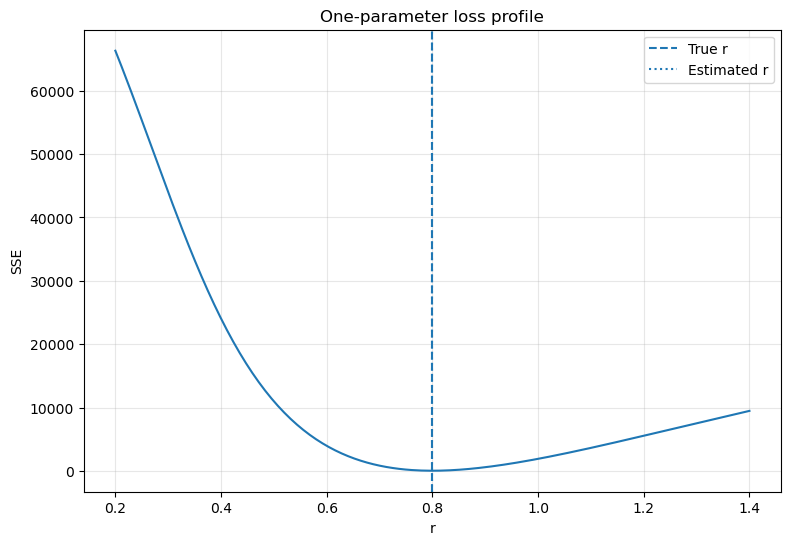

In [26]:
r_grid = np.linspace(
    0.2,
    1.4,
    200
)

loss_grid_r = np.array([
    loss_r_only(r)
    for r in r_grid
])

plt.figure(figsize=(9, 6))
plt.plot(
    r_grid,
    loss_grid_r
)
plt.axvline(
    R_TRUE,
    linestyle="--",
    label="True r"
)
plt.axvline(
    r_hat_1d,
    linestyle=":",
    label="Estimated r"
)
plt.xlabel("r")
plt.ylabel("SSE")
plt.title("One-parameter loss profile")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 9.1

Проаналізуйте:

1. чи має $J(r)$ виражений minimum;
2. наскільки minimum вузький;
3. наскільки $\hat r$ близьке до $r^*$;
4. що змінилося б за більшого observation noise.

Вузький minimum інтуїтивно означає, що data сильніше обмежують parameter. Але повний statistical uncertainty analysis виконаємо пізніше.

# 10. Two-parameter calibration

Тепер $r$ і $K$ невідомі одночасно:

$$
\hat{\theta}
=
(\hat r,\hat K)
=
\arg\min_{r,K}J(r,K).
$$

In [27]:
initial_guess = np.array([
    0.5,
    80.0
])

bounds = [
    (0.05, 2.0),
    (20.0, 200.0)
]

result_2d = minimize(
    fun=sse_loss,
    x0=initial_guess,
    args=(
        t_obs,
        y_obs,
        X0
    ),
    method="L-BFGS-B",
    bounds=bounds
)

r_hat, K_hat = result_2d.x

print(
    "Optimization success:",
    result_2d.success
)

print(
    "True parameters:",
    (R_TRUE, K_TRUE)
)

print(
    "Estimated parameters:",
    (
        round(r_hat, 4),
        round(K_hat, 4)
    )
)

print(
    "SSE:",
    round(result_2d.fun, 4)
)

Optimization success: True
True parameters: (0.8, 100.0)
Estimated parameters: (np.float64(0.7973), np.float64(100.3908))
SSE: 56.9166


# 11. Calibration fit

Побудуємо trajectory за estimated parameters:

$$
\hat{x}(t)
=
x(t;\hat r,\hat K).
$$

Calibration RMSE: 1.6463


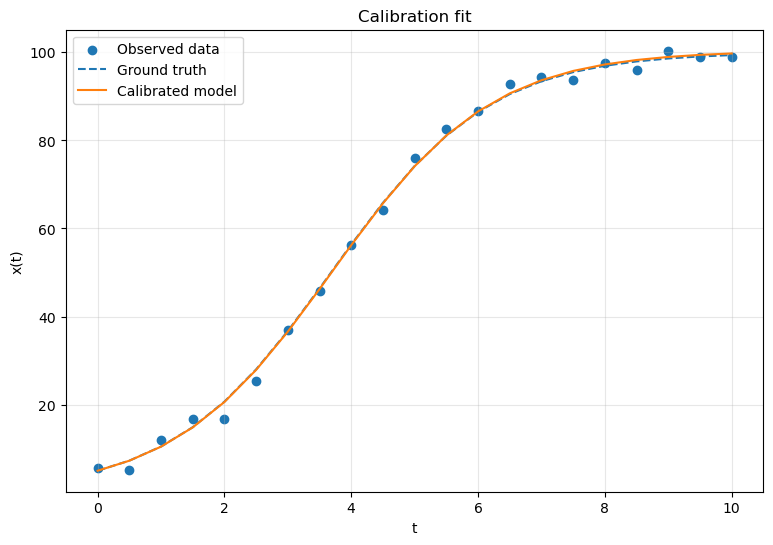

In [28]:
x_calibrated = simulate_logistic(
    t_obs,
    r=r_hat,
    K=K_hat,
    x0=X0
)

print(
    "Calibration RMSE:",
    round(
        rmse(
            y_obs,
            x_calibrated
        ),
        4
    )
)

plt.figure(figsize=(9, 6))
plt.scatter(
    t_obs,
    y_obs,
    label="Observed data"
)
plt.plot(
    t_obs,
    x_true,
    linestyle="--",
    label="Ground truth"
)
plt.plot(
    t_obs,
    x_calibrated,
    label="Calibrated model"
)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.title("Calibration fit")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

::: callout-warning
## Важливо

Хороший calibration fit означає лише:

$$
\text{model with }\hat{\theta}
\text{ добре відтворює calibration data}.
$$

Це ще не означає:

$$
\text{model is validated}.
$$

Validation потребує окремої постановки, intended use, validation data та metrics. Це предмет Теми 9 і ЛР6 [@oberkampfRoy2010].
:::

# 12. Residual analysis

Residual:

$$
e_i
=
y_i-\hat y_i.
$$

Якщо residuals мають systematic pattern, це може свідчити про:

- model discrepancy;
- misspecified observation model;
- missing dynamics;
- nonstationary variance;
- numerical або data problems.

In [29]:
residuals = (
    y_obs
    - x_calibrated
)

residual_table = pd.DataFrame({
    "t": t_obs,
    "observed": y_obs,
    "predicted": x_calibrated,
    "residual": residuals
})

residual_table.head()

,t,observed,predicted,residual
0,0.0,5.609434,5.000000,0.609434
1,0.5,5.200129,7.271723,-2.071594
2,1.0,11.986105,10.462385,1.523719
3,1.5,16.756127,14.830076,1.926052
4,2.0,16.776031,20.603380,-3.827349


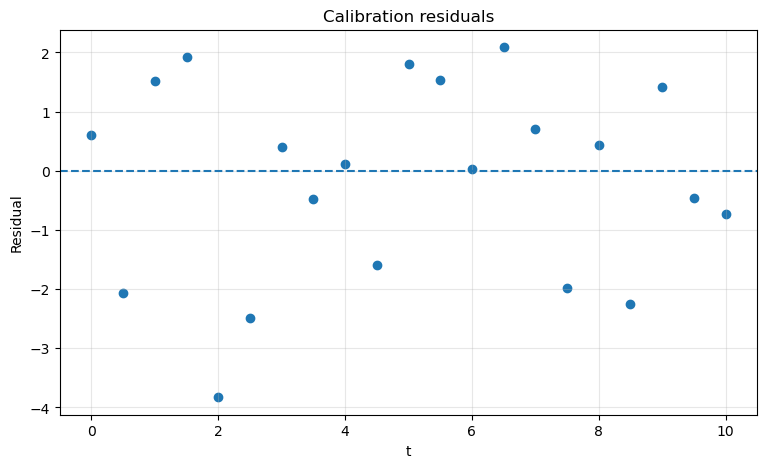

In [30]:
plt.figure(figsize=(9, 5))
plt.axhline(
    0.0,
    linestyle="--"
)
plt.scatter(
    t_obs,
    residuals
)
plt.xlabel("t")
plt.ylabel("Residual")
plt.title("Calibration residuals")
plt.grid(alpha=0.3)
plt.show()

## Завдання 12.1

Перевірте:

- чи residuals centered around zero;
- чи є trend;
- чи змінюється їх spread у часі;
- чи є isolated large residuals.

Не робіть висновок «модель правильна» лише через візуально малий residual.

# 13. Loss surface

Для двох параметрів важливо дослідити

$$
J(r,K).
$$

Якщо surface має вузький isolated basin, параметри краще визначаються data.

Якщо існує довга valley, різні combinations $(r,K)$ можуть давати подібний fit.

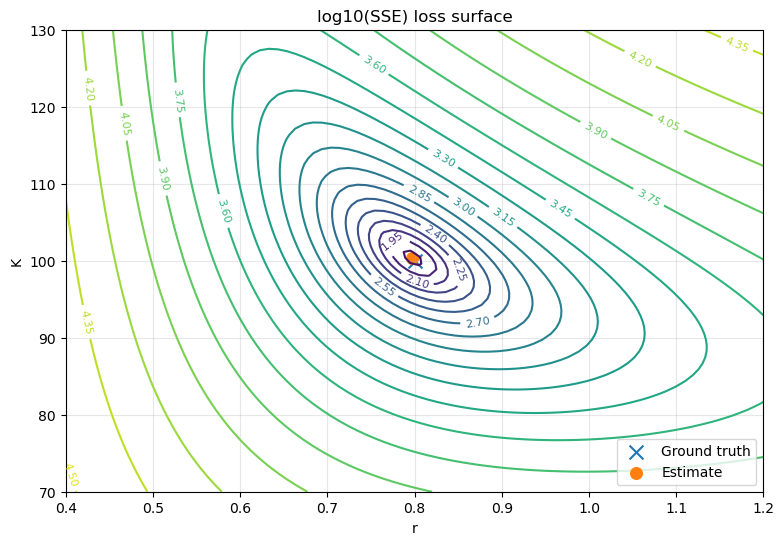

In [31]:
r_values = np.linspace(
    0.4,
    1.2,
    80
)

K_values = np.linspace(
    70.0,
    130.0,
    80
)

loss_surface = np.empty(
    (
        len(K_values),
        len(r_values)
    )
)

for i, K in enumerate(K_values):
    for j, r in enumerate(r_values):
        loss_surface[i, j] = sse_loss(
            (r, K),
            t_obs,
            y_obs,
            X0
        )

R_grid, K_grid = np.meshgrid(
    r_values,
    K_values
)

plt.figure(figsize=(9, 6))
contours = plt.contour(
    R_grid,
    K_grid,
    np.log10(loss_surface),
    levels=20
)
plt.clabel(
    contours,
    inline=True,
    fontsize=8
)
plt.scatter(
    [R_TRUE],
    [K_TRUE],
    marker="x",
    s=100,
    label="Ground truth"
)
plt.scatter(
    [r_hat],
    [K_hat],
    marker="o",
    s=70,
    label="Estimate"
)
plt.xlabel("r")
plt.ylabel("K")
plt.title("log10(SSE) loss surface")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 14. Structural і practical identifiability

*Структурна ідентифікованість (structural identifiability)* питає:

> За ідеальних, noise-free і достатніх observations чи може parameter vector бути однозначно відновлений із model output?

*Практична ідентифікованість (practical identifiability)* питає:

> Чи дозволяють конкретні finite, noisy data достатньо точно визначити parameters?

Тобто:

$$
\text{structurally identifiable}
\not\Rightarrow
\text{practically identifiable}.
$$

У цій лабораторній ми робимо насамперед *practical identifiability audit*.

# 15. Недостатньо інформативні дані

Візьмемо лише ранню частину trajectory:

$$
t\le2.
$$

На цьому interval система ще далеко від saturation, тому $K$ може бути слабко визначеним.

In [32]:
mask_early = t_obs <= 2.0

t_early = t_obs[mask_early]
y_early = y_obs[mask_early]

result_early = minimize(
    fun=sse_loss,
    x0=np.array([
        0.5,
        80.0
    ]),
    args=(
        t_early,
        y_early,
        X0
    ),
    method="L-BFGS-B",
    bounds=bounds
)

print(
    "Full-data estimate:",
    (
        round(r_hat, 4),
        round(K_hat, 4)
    )
)

print(
    "Early-data estimate:",
    tuple(
        np.round(
            result_early.x,
            4
        )
    )
)

Full-data estimate: (np.float64(0.7973), np.float64(100.3908))
Early-data estimate: (np.float64(1.3632), np.float64(21.5384))


# 16. Loss surface для early data

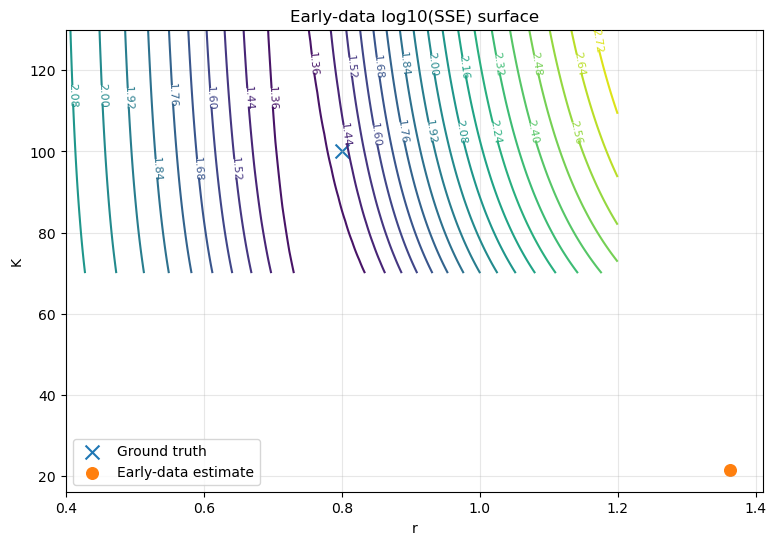

In [33]:
early_surface = np.empty(
    (
        len(K_values),
        len(r_values)
    )
)

for i, K in enumerate(K_values):
    for j, r in enumerate(r_values):
        early_surface[i, j] = sse_loss(
            (r, K),
            t_early,
            y_early,
            X0
        )

plt.figure(figsize=(9, 6))
contours = plt.contour(
    R_grid,
    K_grid,
    np.log10(early_surface),
    levels=20
)
plt.clabel(
    contours,
    inline=True,
    fontsize=8
)
plt.scatter(
    [R_TRUE],
    [K_TRUE],
    marker="x",
    s=100,
    label="Ground truth"
)
plt.scatter(
    [result_early.x[0]],
    [result_early.x[1]],
    marker="o",
    s=70,
    label="Early-data estimate"
)
plt.xlabel("r")
plt.ylabel("K")
plt.title("Early-data log10(SSE) surface")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 16.1

Порівняйте full-data та early-data surfaces.

Поясніть:

1. який parameter визначається гірше;
2. чому early trajectory містить мало інформації про saturation level;
3. чому додавання optimizer iterations не вирішує information deficit.

Ключова ідея:

$$
\text{optimization problem}
\neq
\text{identifiability problem}.
$$

# 17. Multi-start calibration

Якщо різні initial guesses приводять до різних parameter estimates з близькими loss values, це важливий diagnostic signal.

Виконаємо multi-start optimization.

In [34]:
initial_guesses = [
    (0.2, 40.0),
    (0.4, 80.0),
    (0.8, 100.0),
    (1.2, 150.0),
    (1.8, 190.0)
]

multi_start_records = []

for guess in initial_guesses:
    result = minimize(
        fun=sse_loss,
        x0=np.array(guess),
        args=(
            t_obs,
            y_obs,
            X0
        ),
        method="L-BFGS-B",
        bounds=bounds
    )

    multi_start_records.append({
        "r0": guess[0],
        "K0": guess[1],
        "r_hat": result.x[0],
        "K_hat": result.x[1],
        "SSE": result.fun,
        "success": result.success
    })

multi_start = pd.DataFrame(
    multi_start_records
)

multi_start.round(4)

,r0,K0,r_hat,K_hat,SSE,success
0,0.2,40.0,0.7973,100.3908,56.9166,True
1,0.4,80.0,0.7973,100.3908,56.9166,True
2,0.8,100.0,0.7973,100.3908,56.9166,True
3,1.2,150.0,0.7973,100.3908,56.9166,True
4,1.8,190.0,0.7973,100.3908,56.9166,True


## Завдання 17.1

Оцініть:

- чи всі starts приводять до одного minimum;
- чи відрізняються parameter estimates;
- чи відрізняються loss values;
- чи можна довіряти одному optimization run.

# 18. Calibration bounds -- це частина постановки

Ми використали:

$$
0.05\le r\le2,
$$

$$
20\le K\le200.
$$

Bounds не є технічною дрібницею.

Вони кодують prior domain knowledge або physical admissibility.

Якщо optimum лежить на boundary, потрібно запитати:

- чи boundary занадто вузька;
- чи parameter practically non-identifiable;
- чи model structure не відповідає data;
- чи optimizer знайшов numerical artifact.

# 19. Over-calibration

Збільшення кількості parameters майже завжди може зменшити calibration loss.

Але:

$$
J_{\text{smaller}}
\not\Rightarrow
\text{better scientific model}.
$$

Додаткові parameters можуть:

- компенсувати model discrepancy;
- стати non-identifiable;
- погіршити predictive behavior;
- ускладнити interpretation;
- створити false precision.

Тому calibration має бути пов'язана з *мінімально достатньою model architecture*, яку ми обговорювали в Лекції 5.

# 20. Що ми насправді оцінили?

У synthetic case ми знаємо:

$$
\theta^*=(r^*,K^*).
$$

У реальному дослідженні маємо лише:

$$
\hat{\theta}
=
\arg\min J(\theta).
$$

Отже, потрібно розрізняти:

$$
\text{true parameter}
\neq
\text{estimated parameter}
\neq
\text{effective parameter}.
$$

У складних моделях calibrated parameter інколи є effective quantity, що частково компенсує unresolved mechanisms.

# 21. Критичний аудит навчального кейсу

| Питання | Відповідь |
|---|---|
| Яка model structure? | |
| Які states? | |
| Які unknown parameters? | |
| Які parameters fixed? | |
| Який observation model? | |
| Який noise assumption? | |
| Яка loss function? | |
| Які parameter bounds? | |
| Який optimizer? | |
| Який initial guess? | |
| Чи використано multi-start? | |
| Який calibration RMSE? | |
| Що показують residuals? | |
| Що показує loss surface? | |
| Які parameters practically identifiable? | |
| Як data window впливає на identifiability? | |
| Чи використано незалежні validation data? | |
| Що ще не можна стверджувати про модель? | |

::: callout-tip
## Методологічний результат

Коректна calibration workflow має вигляд:

$$
\text{RQ}
\rightarrow
\text{model structure}
\rightarrow
\text{observation model}
\rightarrow
\text{loss}
\rightarrow
\text{optimization}
\rightarrow
\text{diagnostics}
\rightarrow
\text{identifiability audit}.
$$

Оптимізатор -- лише один елемент цього ланцюжка.
:::

# Частина II. Перенесення на дисертаційне дослідження

# 22. Чи є у Вашій моделі параметри, які потрібно оцінювати?

Визначте parameter vector:

$$
\theta
=
(\theta_1,\ldots,\theta_p).
$$

Для кожного parameter вкажіть:

- physical / domain meaning;
- units;
- admissible range;
- fixed або calibrated;
- data source;
- expected influence on output.

# 23. Direct problem

Запишіть:

$$
\theta
\rightarrow
\hat{\mathbf{y}}(\theta).
$$

Чітко визначте:

- inputs;
- initial conditions;
- model solver;
- outputs;
- quantity compared with observations.

# 24. Observation model

Опишіть relation між latent model state та observed data:

$$
y_i
=
h(x(t_i;\theta))
+
\varepsilon_i.
$$

Поясніть:

- що саме вимірюється;
- з якою frequency;
- які transformations застосовуються;
- які missing values можливі;
- який error mechanism припускається.

# 25. Loss function

Запишіть власну objective function:

$$
J(\theta).
$$

Обґрунтуйте, чому вона відповідає data type і Research Question.

Можливі варіанти:

- SSE / MSE;
- weighted SSE;
- negative log-likelihood;
- robust loss;
- multi-objective criterion.

Не обирайте metric лише тому, що вона є default у бібліотеці.

# 26. Parameter bounds і constraints

Для кожного $\theta_j$ вкажіть:

| Parameter | Meaning | Lower bound | Upper bound | Justification |
|---|---|---:|---:|---|
| $\theta_1$ | | | | |
| $\theta_2$ | | | | |
| ... | | | | |

# 27. Calibration protocol

Зафіксуйте:

| Елемент | Специфікація |
|---|---|
| Calibration dataset | |
| Observation window | |
| Preprocessing | |
| Loss function | |
| Optimizer | |
| Initial guess policy | |
| Bounds / constraints | |
| Solver tolerances | |
| Random seed, якщо є | |
| Stopping criterion | |

# 28. Calibration diagnostics

Мінімально перевірте:

1. fitted trajectory / outputs;
2. residuals;
3. loss profile хоча б для одного ключового parameter;
4. multi-start behavior;
5. boundary solutions;
6. parameter plausibility.

Якщо parameters два -- побудуйте loss surface.

Якщо parameters більше -- використайте pairwise profiles або інший обґрунтований diagnostic.

# 29. Practical identifiability audit

Для кожного parameter дайте оцінку:

| Parameter | Well constrained? | Evidence | Problem |
|---|---|---|---|
| $\theta_1$ | | | |
| $\theta_2$ | | | |

Не використовуйте лише формулювання «optimizer converged».

Convergence означає:

$$
\text{algorithm stopped successfully},
$$

а не:

$$
\text{parameter is scientifically identified}.
$$

# 30. Data informativeness experiment

Змініть одну характеристику data:

- observation window;
- sampling frequency;
- noise level;
- кількість observations;
- measured variable.

Повторіть calibration.

Порівняйте:

$$
\hat{\theta}^{(A)}
\quad\text{vs}\quad
\hat{\theta}^{(B)}.
$$

Поясніть, яка data characteristic найбільше впливає на parameter recovery.

# 31. Calibration Specification v0.5

| Компонент | Специфікація v0.5 |
|---|---|
| Research Question | |
| Model architecture | |
| State variables | |
| Parameter vector | |
| Fixed parameters | |
| Calibrated parameters | |
| Observation model | |
| Calibration dataset | |
| Loss function | |
| Bounds / constraints | |
| Optimization method | |
| Initial guess policy | |
| Multi-start protocol | |
| Residual diagnostics | |
| Loss-profile diagnostics | |
| Practical identifiability | |
| Data informativeness | |
| Calibration limitations | |
| Reproducibility metadata | |

# 32. Підсумковий артефакт ЛР5

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Model<br/>architecture") --> B("Calibration<br/>data")
 B --> C("Observation<br/>model")
 C --> D("Loss<br/>function")
 D --> E("Parameter<br/>estimation")
 E --> F("Residual + loss<br/>diagnostics")
 F --> G("Identifiability<br/>audit")
 G --> H("Calibration<br/>Specification v0.5")
```

# Контрольні питання

1. Чим direct problem відрізняється від inverse problem?
2. Що називають parameter identification?
3. Що таке calibration?
4. Чим model structure відрізняється від parameter values?
5. Що таке observation model?
6. Чим measurement noise відрізняється від process stochasticity?
7. Що таке loss function?
8. Як інтерпретується SSE?
9. Чим SSE відрізняється від RMSE?
10. Що означає $\arg\min$?
11. Для чого потрібен loss profile?
12. Що показує loss surface?
13. Що таке structural identifiability?
14. Що таке practical identifiability?
15. Чому structural identifiability не гарантує practical identifiability?
16. Чому ранні observations logistic growth погано визначають $K$?
17. Чому більше optimizer iterations не компенсує неінформативні data?
18. Навіщо multi-start calibration?
19. Що означає optimizer convergence?
20. Чому convergence не є доказом identifiability?
21. Яку роль відіграють parameter bounds?
22. Що може означати optimum на boundary?
23. Для чого аналізувати residuals?
24. Що таке model discrepancy?
25. Чим calibration fit відрізняється від validation?
26. Що таке over-calibration?
27. Чому додаткові parameters можуть погіршити scientific credibility?
28. Чим estimated parameter може відрізнятися від physical parameter?
29. Що таке data informativeness?
30. Які елементи повинна містити Calibration Specification v0.5?

# Вимоги до звіту

У `.ipynb` мають бути:

- Research Question;
- model structure;
- parameter vector;
- synthetic або empirical calibration data;
- observation model;
- direct problem;
- inverse problem;
- loss function;
- one-parameter calibration;
- loss profile;
- multi-parameter calibration;
- calibrated trajectory;
- residual analysis;
- loss surface або його обґрунтований аналог;
- multi-start experiment;
- data informativeness experiment;
- practical identifiability audit;
- перенесення на дисертаційний кейс;
- *Calibration Specification v0.5*;
- висновки.

::: callout-important
## Критерій якості

Оцінюється не здатність викликати `scipy.optimize.minimize`, а коректність дослідницького ланцюжка:

$$
\text{model}
\rightarrow
\text{data}
\rightarrow
\text{inverse problem}
\rightarrow
\text{calibration}
\rightarrow
\text{diagnostics}
\rightarrow
\text{identifiability}.
$$
:::

# Висновки

У висновках дайте відповіді:

1. Які parameters калібрувалися?
2. Які observations використано?
3. Яку observation model прийнято?
4. Яку loss function використано?
5. Які parameter estimates отримано?
6. Чи залежить результат від initial guess?
7. Що показують residuals?
8. Що показує loss surface?
9. Які parameters practically identifiable?
10. Як data window впливає на parameter recovery?
11. Які calibration limitations залишаються?
12. Чому отриманий fit ще не є validation?

# Джерела та корисні ресурси

Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [SciPy -- solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html)
- [SciPy -- minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
- [SciPy -- minimize_scalar](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [pandas documentation](https://pandas.pydata.org/docs/)
- [Matplotlib documentation](https://matplotlib.org/stable/)

# References